In [48]:
import json
import os

import gc_utils
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.cosmology import LambdaCDM, default_cosmology
from scipy.interpolate import interp1d

# plt.rc("font", family="Nimbus Roman")
plt.rc("font", family="Nimbus Roman No9 L")

SMALL_SIZE = 7
MEDIUM_SIZE = 7
BIGGER_SIZE = 7

plt.rc("font", size=SMALL_SIZE)  # controls default text sizes
plt.rc("axes", titlesize=SMALL_SIZE)  # fontsize of the axes title
plt.rc("axes", labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc("xtick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("ytick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("legend", fontsize=SMALL_SIZE)  # legend fontsize
plt.rc("figure", titlesize=BIGGER_SIZE)  # fontsize of the figure title

In [49]:
sim_lst = ["m12b", "m12c", "m12f", "m12i", "m12m"]
sim_dir = "/Users/z5114326/Documents/simulations/"

# bands = ["jwst_f150w", "jwst_f444w"]
# bands = ["jwst_f115w"]

snap = 600
min_mass = 1e4

scmap = plt.get_cmap("tab10")
colors = [scmap(i) for i in np.linspace(0, 1, len(sim_lst))]
sim_colors = {sim: colors[i] for i, sim in enumerate(sim_lst)}

In [50]:
public_snapshot_file = sim_dir + "snapshot_times_public.txt"
pub_data = pd.read_table(public_snapshot_file, comment="#", header=None, sep=r"\s+")
pub_data.columns = [
    "index",
    "scale_factor",
    "redshift",
    "time_Gyr",
    "lookback_time_Gyr",
    "time_width_Myr",
]
timez0 = float(pub_data[pub_data["index"] == snap]["time_Gyr"].values[0])
pub_snaps = np.array(pub_data["index"])

all_data_fil = sim_dir + "/" + "m12i" + "/" + "m12i" + "_res7100/" + "snapshot_times.txt"
all_data = pd.read_table(all_data_fil, comment="#", header=None, sep=r"\s+")
all_data.columns = [
    "index",
    "scale_factor",
    "redshift",
    "time_Gyr",
    "lookback_time_Gyr",
    "time_width_Myr",
]
all_times = np.array(all_data["time_Gyr"])
all_snaps = np.array(all_data["index"])

snap_times = {
    gc_utils.snapshot_name(s): float(pub_data.loc[pub_data["index"] == s, "time_Gyr"].values[0])
    for s in pub_snaps
}

In [51]:
sim_dict = {}

# ------------------------------------------------
# precompute snapshot times once
# ------------------------------------------------
snap_times = {
    gc_utils.snapshot_name(s): float(pub_data.loc[pub_data["index"] == s, "time_Gyr"].values[0])
    for s in pub_snaps
}

timez0 = snap_times[gc_utils.snapshot_name(snap)]

for sim in sim_lst:
    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
    sim_dict[sim] = {}

    with h5py.File(ghost_file, "r") as ghost_data:
        for it_id, it_grp in ghost_data.items():
            src = it_grp["source"]

            # ---------------------------
            # read once
            # ---------------------------
            grpid = src["grpid"][()]
            amsk = grpid == 0

            logm_tfor = src["logm_tfor"][()]
            logm_tz0 = src["logm_tz0"][()]

            m_tfo = 10.0**logm_tfor
            m_tfo_ev = 0.55 * m_tfo  # stellar-evolution corrected mass

            m_tz0 = np.zeros_like(logm_tz0, dtype=float)
            msk = logm_tz0 != -1
            m_tz0[msk] = 10.0 ** logm_tz0[msk]

            tfor = src["tfor"][()]
            tdis = src["tdis"][()]
            tacc = src["tacc"][()]
            feh = src["feh"][()]
            gcids = src["gcid"][()]

            tdis = np.where(tdis == -1, np.inf, tdis)

            rz0 = np.linalg.norm(src["pxyz_snap600"][()], axis=1)

            # ---------------------------
            # vectorized ages
            # ---------------------------
            age = timez0 - tfor
            age_p = np.where(np.isfinite(tdis), tdis - tfor, age)

            t_tz0 = src["torb_600"][()]
            s_tz0 = src["s_flag"][()].astype(bool)
            sa_flag = src["sa_flag"][()].astype(bool)

            # ---------------------------
            # snapshot mass table
            #   + tfor (m_tfo_ev)
            #   + tdis (0)
            # ---------------------------
            n_gc = len(gcids)
            n_snap = len(pub_snaps)

            mass_arr = np.full((n_gc, n_snap + 2), np.nan)
            time_arr = np.full((n_gc, n_snap + 2), np.nan)

            # ---- formation point ----
            mass_arr[:, 0] = m_tfo_ev
            time_arr[:, 0] = tfor

            # ---- simulation snapshots ----
            for j, (snap_id, time) in enumerate(snap_times.items(), start=1):
                snp = it_grp["snapshots"][snap_id]
                snp_gcids = snp["gcid"][()]
                snp_mass = 10.0 ** snp["logm"][()]

                common, idx_snp, idx_src = np.intersect1d(snp_gcids, gcids, return_indices=True)

                mass_arr[idx_src, j] = snp_mass[idx_snp]
                time_arr[idx_src, j] = time

                # ---- disruption point (only if disrupted) ----
                has_disrupted = np.isfinite(tdis)

                mass_arr[has_disrupted, -1] = 0.0
                time_arr[has_disrupted, -1] = tdis[has_disrupted]

            # ---------------------------
            # final mass cut
            # ---------------------------
            m_tfo_msk = m_tfo >= min_mass

            sim_dict[sim][it_id] = {
                "gcid": gcids[m_tfo_msk],
                "feh": feh[m_tfo_msk],
                "tfor": tfor[m_tfo_msk],
                "tdis": tdis[m_tfo_msk],
                "tacc": tacc[m_tfo_msk],
                "age": age[m_tfo_msk],
                "age_p": age_p[m_tfo_msk],
                "rz0": rz0[m_tfo_msk],
                "t_tz0": t_tz0[m_tfo_msk],
                "s_tz0": s_tz0[m_tfo_msk],
                "sa_flag": sa_flag[m_tfo_msk],
                "acc": amsk[m_tfo_msk],
                # ---- masses ----
                "m_tfo": m_tfo[m_tfo_msk],
                "m_tfo_ev": m_tfo_ev[m_tfo_msk],
                "m_tz0": m_tz0[m_tfo_msk],
                # ---- time-resolved mass history ----
                "m_snp": mass_arr[m_tfo_msk],
                "t_snp": time_arr[m_tfo_msk],
            }

In [52]:
def build_mass_interpolators(dat):
    interps = []

    for m, t in zip(dat["m_snp"], dat["t_snp"]):
        # keep the disruption point (m=0 at tdis)
        msk = np.isfinite(m)

        if np.sum(msk) < 2:
            interps.append(None)
            continue

        order = np.argsort(t[msk])

        ts = t[msk][order]
        ms = m[msk][order]

        interps.append(
            interp1d(
                ts,
                ms,
                kind="linear",
                bounds_error=False,
                fill_value=(ms[0], 0.0),
            )
        )

    return interps


for sim in sim_lst:
    for it_id in sim_dict[sim]:
        sim_dict[sim][it_id]["mass_interp"] = build_mass_interpolators(sim_dict[sim][it_id])

In [55]:
# ==========================================================
# TOTAL DEBRIS MASS EVOLUTION
# FIXED: clusters contribute zero debris before formation
# ==========================================================

tim_lst = np.arange(0.0, 14.0, 0.1)

debris_dict = {}

for sim in sim_lst:
    debris_iter = []

    for it_id in sim_dict[sim]:
        dat = sim_dict[sim][it_id]

        mfor = dat["m_tfo_ev"]
        tfor = dat["tfor"]

        debris_hist = np.zeros_like(tim_lst)

        for m0, tf, interp in zip(mfor, tfor, dat["mass_interp"]):
            if interp is None:
                continue

            # Evaluate entire time grid
            m_alive = interp(tim_lst)

            # Debris contributed by this cluster
            debris = np.zeros_like(tim_lst)

            formed = tim_lst >= tf

            # Before formation: debris = 0
            # After formation: debris = mform - malive
            debris[formed] = m0 - m_alive[formed]

            debris_hist += debris

        debris_iter.append(debris_hist)

    debris_iter = np.asarray(debris_iter)

    debris_dict[sim] = {
        "median": np.median(debris_iter, axis=0),
        "p16": np.percentile(debris_iter, 16, axis=0),
        "p84": np.percentile(debris_iter, 84, axis=0),
    }

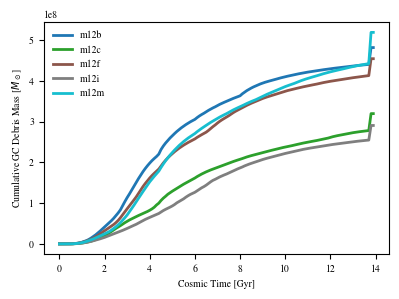

In [57]:
# ==========================================================
# PLOT
# ==========================================================

fig, ax = plt.subplots(figsize=(4, 3))

for sim in sim_lst:
    med = debris_dict[sim]["median"]
    p16 = debris_dict[sim]["p16"]
    p84 = debris_dict[sim]["p84"]

    ax.plot(tim_lst, med, color=sim_colors[sim], lw=2, label=sim)
    # ax.fill_between(tim_lst, p16, p84, color=sim_colors[sim], alpha=0.2)

ax.set_xlabel("Cosmic Time [Gyr]")
ax.set_ylabel(r"Cumulative GC Debris Mass [$M_\odot$]")

ax.legend(frameon=False, fontsize=7)

# ax.set_yscale("log")

plt.tight_layout()
plt.show()


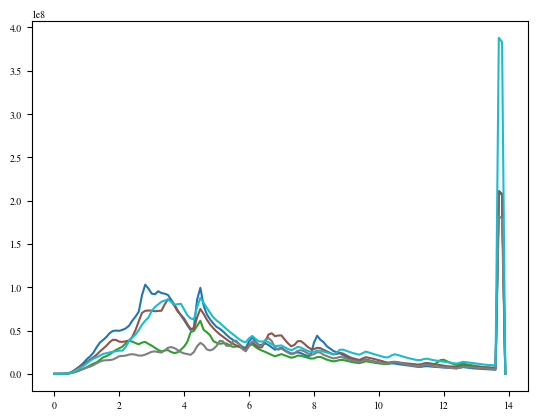

In [58]:
for sim in sim_lst:
    plt.plot(tim_lst, np.gradient(debris_dict[sim]["median"], tim_lst), c=sim_colors[sim])

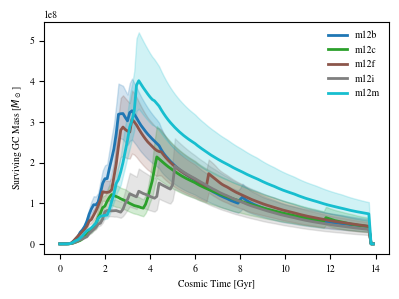

In [59]:
# ==========================================================
# SURVIVING GC MASS EVOLUTION
# ==========================================================

tim_lst = np.arange(0.0, 14.0, 0.1)

surv_dict = {}

for sim in sim_lst:
    surv_iter = []

    for it_id in sim_dict[sim]:
        dat = sim_dict[sim][it_id]

        tfor = dat["tfor"]

        surv_hist = np.zeros_like(tim_lst)

        for tf, interp in zip(
            tfor,
            dat["mass_interp"],
        ):
            if interp is None:
                continue

            # evaluate entire time grid
            m_alive = interp(tim_lst)

            # cluster does not exist before formation
            m_alive[tim_lst < tf] = 0.0

            surv_hist += m_alive

        surv_iter.append(surv_hist)

    surv_iter = np.asarray(surv_iter)

    surv_dict[sim] = {
        "median": np.median(surv_iter, axis=0),
        "p16": np.percentile(surv_iter, 16, axis=0),
        "p84": np.percentile(surv_iter, 84, axis=0),
    }

# ==========================================================
# PLOT
# ==========================================================

fig, ax = plt.subplots(figsize=(4, 3))

for sim in sim_lst:
    med = surv_dict[sim]["median"]
    p16 = surv_dict[sim]["p16"]
    p84 = surv_dict[sim]["p84"]

    ax.plot(
        tim_lst,
        med,
        color=sim_colors[sim],
        lw=2,
        label=sim,
    )

    ax.fill_between(
        tim_lst,
        p16,
        p84,
        color=sim_colors[sim],
        alpha=0.2,
    )

ax.set_xlabel("Cosmic Time [Gyr]")
ax.set_ylabel(r"Surviving GC Mass [$M_\odot$]")

ax.legend(
    frameon=False,
    fontsize=7,
)

plt.tight_layout()
plt.show()

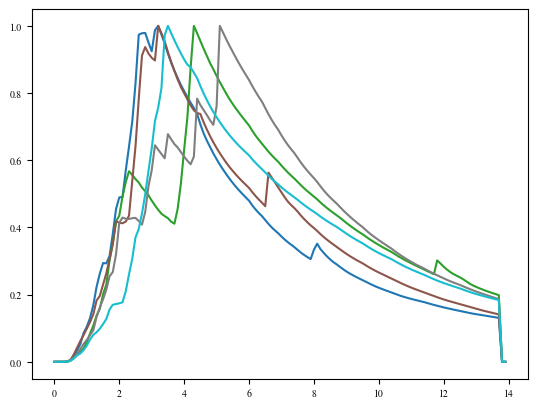

In [60]:
for sim in sim_lst:
    m = surv_dict[sim]["median"]

    f = m / np.max(m)

    plt.plot(tim_lst, f, color=sim_colors[sim], label=sim)

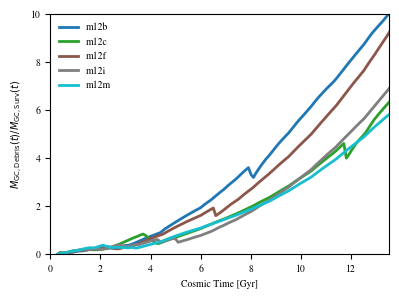

In [61]:
# ==========================================================
# R(t) = M_debris(t) / M_surv(t)
# ==========================================================

fig, ax = plt.subplots(figsize=(4, 3))

for sim in sim_lst:
    debris = debris_dict[sim]["median"]
    surv = surv_dict[sim]["median"]

    msk = surv > 0

    R = np.full_like(surv, np.nan)
    R[msk] = debris[msk] / surv[msk]

    ax.plot(tim_lst, R, lw=2, color=sim_colors[sim], label=sim)

ax.set_xlabel("Cosmic Time [Gyr]")
ax.set_ylabel(r"$M_{\rm GC,Debris}(t) / M_{\rm GC,Surv}(t)$")

ax.legend(frameon=False, fontsize=7)

ax.set_xlim(0, 13.5)
ax.set_ylim(0, 10)

plt.tight_layout()
plt.show()


In [62]:
# ==========================================================
# BUILD TIDAL-FIELD HISTORIES
# ==========================================================

tidal_dict = {}

for sim in sim_lst:
    print(sim)
    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"

    with h5py.File(ghost_file, "r") as ghost_data:
        first_it = next(iter(ghost_data.keys()))
        snap_ids = list(ghost_data[first_it]["snapshots"].keys())

        tvals = []
        lam_median = []
        lam_p16 = []
        lam_p84 = []

        for snap_id in snap_ids:
            lam_iter = []

            for it_id in ghost_data.keys():
                src = ghost_data[it_id]["source"]
                snp = ghost_data[it_id]["snapshots"][snap_id]

                # in-situ mask from source catalogue
                insitu_ids = src["gcid"][src["grpid"][()] == 0]

                gcids = snp["gcid"][()]
                masses = 10 ** snp["logm"][()]
                tideig = snp["tideig"][()]

                common, idx_snp, _ = np.intersect1d(
                    gcids,
                    insitu_ids,
                    return_indices=True,
                )

                if len(common) == 0:
                    continue

                lam_iter.append(np.average(tideig[idx_snp]))
                # lam_iter.append(np.median(tideig[idx_snp]))

            if len(lam_iter) == 0:
                continue

            snap_num = int(snap_id.replace("snap", ""))

            snap_name = gc_utils.snapshot_name(snap_num)

            tvals.append(snap_times[snap_name])

            lam_median.append(np.median(lam_iter))

            lam_p16.append(np.percentile(lam_iter, 16))

            lam_p84.append(np.percentile(lam_iter, 84))

        tidal_dict[sim] = {
            "time": np.asarray(tvals),
            "median": np.asarray(lam_median),
            "p16": np.asarray(lam_p16),
            "p84": np.asarray(lam_p84),
        }

m12b
m12c
m12f
m12i
m12m


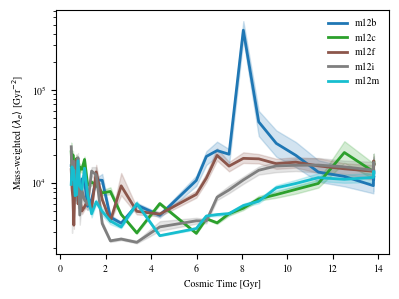

In [63]:
# ==========================================================
# PLOT TIDAL-FIELD HISTORIES
# ==========================================================

fig, ax = plt.subplots(
    1,
    1,
    figsize=(4, 3),
)

for sim in sim_lst:
    dat = tidal_dict[sim]

    order = np.argsort(dat["time"])

    t = dat["time"][order]
    med = dat["median"][order]
    p16 = dat["p16"][order]
    p84 = dat["p84"][order]

    ax.plot(
        t,
        med,
        lw=2,
        color=sim_colors[sim],
        label=sim,
    )

    ax.fill_between(
        t,
        p16,
        p84,
        color=sim_colors[sim],
        alpha=0.2,
    )

ax.set_yscale("log")

ax.set_xlabel("Cosmic Time [Gyr]")
ax.set_ylabel(r"Mass-weighted $\langle \lambda_e \rangle$ [Gyr$^{-2}$]")

ax.legend(
    frameon=False,
    fontsize=7,
)

plt.tight_layout()
plt.show()

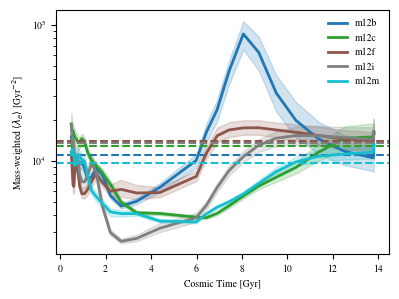

In [ ]:
from scipy.ndimage import gaussian_filter1d

# ==========================================================
# PLOT TIDAL-FIELD HISTORIES (SMOOTHED)
# ==========================================================

fig, ax = plt.subplots(
    1,
    1,
    figsize=(4, 3),
)

sigma = 1.0  # increase to 1.5-2 for stronger smoothing

for sim in sim_lst:
    dat = tidal_dict[sim]

    order = np.argsort(dat["time"])

    t = dat["time"][order]
    med = dat["median"][order]
    p16 = dat["p16"][order]
    p84 = dat["p84"][order]

    # smooth in log-space
    log_med = gaussian_filter1d(np.log10(med), sigma=sigma)
    log_p16 = gaussian_filter1d(np.log10(p16), sigma=sigma)
    log_p84 = gaussian_filter1d(np.log10(p84), sigma=sigma)

    med_s = 10**log_med
    p16_s = 10**log_p16
    p84_s = 10**log_p84

    ax.plot(t, med_s, lw=2, color=sim_colors[sim], label=sim)
    ax.fill_between(t, p16_s, p84_s, color=sim_colors[sim], alpha=0.2)

    mean_t = np.trapz(med, t) / (t[-1] - t[0])
    mean_t = np.mean(med)
    mean_t = np.median(med)
    ax.axhline(mean_t, c=sim_colors[sim], ls="--")

ax.set_yscale("log")

ax.set_xlabel("Cosmic Time [Gyr]")
ax.set_ylabel(r"Mass-weighted $\langle \lambda_e \rangle$ [Gyr$^{-2}$]")

ax.legend(frameon=False, fontsize=7)

plt.tight_layout()
plt.show()

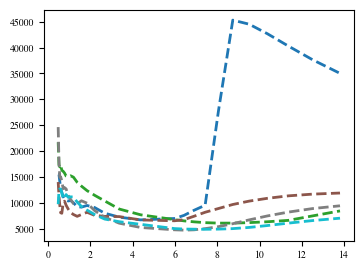

In [ ]:
from scipy.integrate import cumulative_trapezoid

fig, ax = plt.subplots(1, 1, figsize=(4, 3))

for sim in sim_lst:
    dat = tidal_dict[sim]

    order = np.argsort(dat["time"])

    t = dat["time"][order]
    med = dat["median"][order]

    # cumulative integral of lambda(t)
    cum_int = cumulative_trapezoid(
        med,
        t,
        initial=0,
    )

    # running time-averaged tidal field
    running_mean = np.zeros_like(med)
    running_mean[0] = med[0]
    running_mean[1:] = cum_int[1:] / (t[1:] - t[0])

    ax.plot(
        t,
        running_mean,
        ls="--",
        lw=2,
        color=sim_colors[sim],
    )

In [ ]:
import cmasher as cmr

pub_times = np.array(pub_data["time_Gyr"])
pub_snaps = np.array(pub_data["index"])